##### Feladat

Írjuk fel az alábbi síkgörbe rúd igénybevételi függvényeit!

<img src="img/01.jpg" alt="Feladat" width=200px>

##### Csomagok importálása

In [1]:
import numpy as np # Numerikus számítások
import matplotlib.pyplot as plt # Ábrázolás
plt.rcParams['mathtext.fontset'] = 'cm' # Betűtípus az ábrákon
plt.rcParams['font.family'] = 'serif' # Betűtípus az ábrákon
plt.rcParams['font.serif'] = ['cmr10'] # Betűtípus az ábrákon
plt.rcParams['axes.formatter.use_mathtext'] = True # Betűtípus az ábrákon
plt.rcParams['axes.unicode_minus'] = False # Betűtípus az ábrákon
from IPython.display import display, Math, Latex # Szép kimenet Jupyter notebookban
import sympy as sp # Szimbólikus számítások
from sympy import latex # Szép kimenet Jupyter notebookban
sp.init_printing() # Szép kimenet Jupyter notebookban

##### Adatok

In [2]:
# A feladat paraméteresen adott, így az adatokat szimbólumként vesszük fel
R, F_x, F_y = sp.symbols('R, F_x, F_y', positive=True)

# Leíró koordináta
phi = sp.symbols('varphi')

##### Elméleti összefoglaló

* Egyenes rúd: a rúdirányú koordináta $x$, az igénybevételek előjelét az alábbi előjelkonvenció szerint határozzuk meg (lásd a 8.1 feladatot):

<img src="img/02.jpg" alt="Feladat" width=420px>

* Egyenes rúdszerkezet: körbejárjuk a rudat, minden egyenes szakaszon a körbejárás irányába mutató rúdirányú koordinátát veszünk fel ($x_1$, $x_2$, $x_3$) → az előjelkonvenció fordul a körbejárással!

<img src="img/03.jpg" alt="Feladat" width=700px>

* Síkgörbe rudak: olyan rúd, amely nem egyenes szakaszokból áll, hanem véges görbületű szakaszokból.

    * leíró koordináta: $\varphi$ (az ívhossz: $R \varphi$)

    * minden keresztmetszetben az erőket normál irányra (a rúd érintője, $N$) és sugár irányra ($V$) bontjuk

<img src="img/04.jpg" alt="Feladat" width=380px>

* Előjelkonvenció síkgörbe rudaknál: a görbületi középpont ($G$) felől nézve ugyanaz, mint az egyenes rúdnál:

<img src="img/05.jpg" alt="Feladat" width=750px>

* Derivált kapcsolat: egyenes rúdnál $M_h'(x) = -V(x)$, síkgörbe rúdnál az ívhossz ($R \varphi$) szerint deriválunk:

    * ha $\varphi$ az óramutató járásával megegyezik: $\dfrac{\mathrm{d} M_h(\varphi)}{\mathrm{d}(R \varphi)} = -V(\varphi)$

    * ha $\varphi$ az óramutató járásával ellentétes: $\dfrac{\mathrm{d} M_h(\varphi)}{\mathrm{d}(R \varphi)} = +V(\varphi)$

##### Előjelkonvenció

* leíró koordináta: $\varphi$, a szabad végtől mérjük, az óramutató járásával ellentétes irányban ($\varphi \in [0, \pi/2]$)

* balról vagy jobbról is lehet kezdeni: a szabad végtől indulunk, így a befogásban ébredő reakciókat nem kell meghatározni

* a görbületi középpont felől nézve a szabad vég van a jobb oldalon → jobbról redukálunk

Az ábrán a pozitív igénybevételek iránya látható a szabad végen és a befogásnál:

<img src="img/06.jpg" alt="Feladat" width=150px>

##### Redukálás a $K$ keresztmetszetbe

A $\varphi$ szöggel megadott $K$ keresztmetszettől jobbra (a szabad vég felé) csak az $F_x$ és $F_y$ erők hatnak, ezeket redukáljuk a $K$ keresztmetszet súlypontjába:

<img src="img/07.jpg" alt="Feladat" width=250px>

Kinagyítva: az erőket normál és sugár irányú komponensekre bontjuk:

<img src="img/08.jpg" alt="Feladat" width=300px>

##### Komponensek

In [3]:
# Az F_x erő komponensei: sugár irányú (nyíróerő) és normál irányú (normálerő)
F_xV = F_x*sp.sin(phi)
display(Math(rf'F_{{xV}} = {latex(F_xV)}'))

F_xN = F_x*sp.cos(phi)
display(Math(rf'F_{{xN}} = {latex(F_xN)}'))

# Az F_y erő komponensei: sugár irányú (nyíróerő) és normál irányú (normálerő)
F_yV = F_y*sp.cos(phi)
display(Math(rf'F_{{yV}} = {latex(F_yV)}'))

F_yN = F_y*sp.sin(phi)
display(Math(rf'F_{{yN}} = {latex(F_yN)}'))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

##### Hajlítás: erőkarok

A $K$ keresztmetszet súlypontjának távolsága az $F_x$ és az $F_y$ erő hatásvonalától:

<img src="img/09.jpg" alt="Feladat" width=320px>

In [4]:
# Az F_x erő erőkarja: a szabad vég és a K keresztmetszet függőleges távolsága
k_x = R*(1 - sp.cos(phi))
display(Math(rf'k_x = R - R \cdot \cos \varphi = {latex(k_x)}'))

# Az F_y erő erőkarja: a szabad vég és a K keresztmetszet vízszintes távolsága
k_y = R*sp.sin(phi)
display(Math(rf'k_y = {latex(k_y)}'))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

##### Az igénybevételi függvények

Jobbról redukálunk: a normálerő pozitív, ha húzza a keresztmetszetet, a nyíróerő pozitív, ha a görbületi középpont felé mutat, a hajlítónyomaték pedig pozitív, ha az óramutató járásával megegyező.

In [5]:
# Normálerő: az F_xN komponens húzza a keresztmetszetet (jobbról nézve pozitív),
# az F_yN komponens nyomja a keresztmetszetet (jobbról nézve negatív)
N = F_xN - F_yN
display(Math(rf'N(\varphi) = F_{{xN}} - F_{{yN}} = {latex(N)}'))

# Nyíróerő: az F_xV és F_yV komponensek a görbületi középpont felé mutatnak (jobbról nézve pozitív)
V = F_xV + F_yV
display(Math(rf'V(\varphi) = F_{{xV}} + F_{{yV}} = {latex(V)}'))

# Hajlítónyomaték: az F_x és F_y erők nyomatéka a K pontra az óramutató járásával megegyező (jobbról nézve pozitív)
M_h = F_x*k_x + F_y*k_y
display(Math(rf'M_h(\varphi) = F_x \cdot k_x + F_y \cdot k_y = {latex(M_h)}'))

# Csavarónyomaték: nincs rúdirányú nyomaték
M_t = sp.Integer(0)
display(Math(rf'M_t(\varphi) = {latex(M_t)}'))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

##### Ellenőrzés

* A szabad végen ($\varphi = 0$) az igénybevételek közvetlenül az $F_x$ és $F_y$ erőkből adódnak: $N = F_x$, $V = F_y$ és $M_h = 0$.

* Derivált kapcsolat: a $\varphi$ az óramutató járásával ellentétes, így $\dfrac{\mathrm{d} M_h(\varphi)}{\mathrm{d}(R \varphi)} = \dfrac{1}{R} M_h'(\varphi) = V(\varphi)$.

In [6]:
# Az igénybevételek a szabad végen
display(Math(rf'N(\varphi=0) = {latex(N.subs(phi, 0))} \qquad V(\varphi=0) = {latex(V.subs(phi, 0))} \qquad M_h(\varphi=0) = {latex(M_h.subs(phi, 0))}'))

# Derivált kapcsolat: az ívhossz (R φ) szerinti derivált
dM_h = sp.expand(sp.diff(M_h, phi)/R)
display(Math(rf"\frac{{\mathrm{{d}} M_h(\varphi)}}{{\mathrm{{d}}(R \varphi)}} = \frac{{1}}{{R}} M_h'(\varphi) = {latex(dM_h)} \qquad V(\varphi) = {latex(V)}"))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

Látható, hogy az összefüggések teljesülnek.

##### Ellenőrzés: redukálás vektoriálisan

A redukálást vektoriálisan is elvégezhetjük (lásd a 2. gyakorlat vektoriális szorzatát). Az origót a görbületi középpontba ($G$) vesszük fel, a szabad vég jele legyen $B$. A $K$ keresztmetszetbe redukált erőrendszer: $\mathbf{F}_K = \mathbf{F}$ és $\mathbf{M}_K = \mathbf{r}_{KB} \times \mathbf{F}$.

In [7]:
# Helyvektorok (az origó a görbületi középpontban van)
r_B = sp.Matrix([0, R, 0])
r_K = sp.Matrix([-R*sp.sin(phi), R*sp.cos(phi), 0])

# A szabad végen ható erővektor
F_vec = sp.Matrix([F_x, -F_y, 0])
display(Math(rf'\mathbf{{F}} = {latex(F_vec)}'))

# A redukált nyomatékvektor a K keresztmetszetben
M_K = sp.expand((r_B - r_K).cross(F_vec))
display(Math(rf'\mathbf{{M}}_K = \mathbf{{r}}_{{KB}} \times \mathbf{{F}} = {latex(M_K)}'))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

In [8]:
# A pozitív normálerő iránya jobbról: a K keresztmetszettől a szabad vég felé (érintő irány)
e_N = sp.Matrix([sp.cos(phi), sp.sin(phi), 0])

# A pozitív nyíróerő iránya jobbról: a görbületi középpont felé (sugár irány)
e_V = sp.Matrix([sp.sin(phi), -sp.cos(phi), 0])

N_vek = F_vec.dot(e_N)
display(Math(rf'N(\varphi) = \mathbf{{F}} \cdot \mathbf{{e}}_N = {latex(N_vek)}'))

V_vek = F_vec.dot(e_V)
display(Math(rf'V(\varphi) = \mathbf{{F}} \cdot \mathbf{{e}}_V = {latex(V_vek)}'))

# A hajlítónyomaték jobbról az óramutató járásával megegyező irányban (-z irányban) pozitív
M_h_vek = -M_K[2]
display(Math(rf'M_h(\varphi) = -M_{{Kz}} = {latex(M_h_vek)}'))

# Az eltérés a korábbi eredményektől
display(Math(rf'N - N_{{vek}} = {latex(sp.simplify(N - N_vek))} \qquad V - V_{{vek}} = {latex(sp.simplify(V - V_vek))} \qquad M_h - M_{{h,vek}} = {latex(sp.simplify(M_h - M_h_vek))}'))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

Látható, hogy ugyanazt az eredményt kaptuk.

##### Szélsőértékek

* $V(\varphi) > 0$ a teljes tartományon ($F_x, F_y > 0$ és $\varphi \in [0, \pi/2]$) → $M_h(\varphi)$ monoton nő, a legnagyobb értékét a befogásnál ($\varphi = \pi/2$) veszi fel.

* A nyíróerő szélsőértéke ott van, ahol $V'(\varphi) = 0$.

In [9]:
# A hajlítónyomaték a befogásnál
M_hmax = M_h.subs(phi, sp.pi/2)
display(Math(rf'M_h(\varphi=\pi/2) = {latex(sp.factor(M_hmax))}'))

# A nyíróerő szélsőértéke: V'(φ) = 0
dV = sp.diff(V, phi)
display(Math(rf"V'(\varphi) = {latex(dV)} = 0 \quad \longrightarrow \quad \tan \varphi_0 = \frac{{F_x}}{{F_y}}"))

phi_0 = sp.atan(F_x/F_y)
display(Math(rf'\varphi_0 = {latex(phi_0)}'))

V_max = sp.simplify(V.subs(phi, phi_0))
display(Math(rf'V(\varphi_0) = {latex(V_max)}'))

# A normálerő ugyanitt előjelet vált
display(Math(rf'N(\varphi_0) = {latex(sp.simplify(N.subs(phi, phi_0)))}'))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

##### Ábrázolás

Az ábrázoláshoz számértékeket kell helyettesíteni. Az ábrák alakja az $F_x / F_y$ aránytól függ, ezért példaként az $F_x = F_y = 1$ és $R = 1$ esetet ábrázoljuk, a jellemző értékeket pedig szimbolikusan jelöljük.

* A rúd mentén: a függvényértékeket a rúd tengelyvonalára merőlegesen mérjük fel, a pozitív értékeket a görbületi középponttól kifelé.

* Az ívhossz szerint: a vízszintes tengelyen az ívhossz ($s = R \varphi$) van.

In [10]:
def igenybeveteli_abra(ax, f, valtozo, t_0, t_1, s, felirat, lepes=0.1, szin='red'):
    # A függvény kiértékelése numerikusan a [t_0, t_1] tartományon
    t_vals = np.linspace(t_0, t_1, 201)
    f_vals = sp.lambdify(valtozo, f, 'numpy')(t_vals) * np.ones_like(t_vals) # Konstans függvény esetén is tömböt kapunk
    # A vízszintes tengelyen az ívhossz (s) szerint ábrázolunk
    s_vals = sp.lambdify(valtozo, s, 'numpy')(t_vals) * np.ones_like(t_vals)
    # A függvény görbéje (zorder: az s tengely fölé rajzoljuk)
    ax.plot(s_vals, f_vals, color=szin, lw=1.5, zorder=3)
    # Satírozás a görbe és az s tengely között, egyenletes (lepes) távolságonként (mint a kézi rajzokon)
    s_satir = np.arange(s_vals[0], s_vals[-1], lepes)
    ax.vlines(s_satir, 0, np.interp(s_satir, s_vals, f_vals), color=szin, lw=0.8)
    # Lezárás a tartomány két végén
    ax.vlines([s_vals[0], s_vals[-1]], 0, [f_vals[0], f_vals[-1]], color=szin, lw=1.5, zorder=3)
    # Az s tengely
    ax.axhline(0, color='black', lw=1)
    ax.set_ylabel(felirat)
    ax.grid(True, alpha=0.5)

def rud_menti_abra(ax, f, valtozo, t_0, t_1, r, n, skala, lepes=0.1, szin='red'):
    # A függvény, a rúd tengelyvonala (r) és a pozitív oldal felé mutató egységvektor (n) kiértékelése numerikusan
    t_vals = np.linspace(t_0, t_1, 201)
    f_vals = sp.lambdify(valtozo, f, 'numpy')(t_vals) * np.ones_like(t_vals)
    r_vals = np.array([sp.lambdify(valtozo, r_i, 'numpy')(t_vals) * np.ones_like(t_vals) for r_i in r])
    n_vals = np.array([sp.lambdify(valtozo, n_i, 'numpy')(t_vals) * np.ones_like(t_vals) for n_i in n])
    # Az ábra pontjai: a függvényértéket a rúd tengelyvonalára merőlegesen mérjük fel
    p_vals = r_vals + skala*f_vals*n_vals
    # A rúd tengelyvonala
    ax.plot(r_vals[0], r_vals[1], color='black', lw=2)
    # A függvény görbéje (zorder: a rúd fölé rajzoljuk)
    ax.plot(p_vals[0], p_vals[1], color=szin, lw=1.5, zorder=3)
    # Satírozás a görbe és a rúd között, egyenletes (lepes) ívhosszonként (mint a kézi rajzokon)
    ivhossz = np.concatenate([[0], np.cumsum(np.hypot(np.diff(r_vals[0]), np.diff(r_vals[1])))])
    for i in np.searchsorted(ivhossz, np.arange(0, ivhossz[-1], lepes)):
        ax.plot([r_vals[0][i], p_vals[0][i]], [r_vals[1][i], p_vals[1][i]], color=szin, lw=0.8)
    # Lezárás a tartomány két végén
    for i in [0, -1]:
        ax.plot([r_vals[0][i], p_vals[0][i]], [r_vals[1][i], p_vals[1][i]], color=szin, lw=1.5, zorder=3)

def ertek_felirat(ax, szoveg, f, valtozo, t, r, n, skala, eltolas=None, szin='red'):
    # Az ábra pontja a t helyen (kerekítés: a numerikus hiba miatt a 0 ne váltson előjelet)
    f_t = round(float(f.subs(valtozo, t)), 10)
    r_t = np.array([float(r_i.subs(valtozo, t)) for r_i in r])
    n_t = np.array([float(n_i.subs(valtozo, t)) for n_i in n])
    p_t = r_t + skala*f_t*n_t
    ax.plot(p_t[0], p_t[1], 'o', color=szin, ms=3, zorder=10)
    # A feliratot a rúdtól elfelé toljuk el (negatív értéknél a másik oldalra), ha nincs megadva az eltolás
    if eltolas is None:
        eltolas = 5*(n_t if f_t >= 0 else -n_t)
    # Igazítás az eltolás iránya szerint, hogy a felirat ne takarja az ábrát
    ha = 'left' if eltolas[0] > 1.5 else ('right' if eltolas[0] < -1.5 else 'center')
    va = 'bottom' if eltolas[1] > 1.5 else ('top' if eltolas[1] < -1.5 else 'center')
    ax.annotate(szoveg, xy=p_t, xytext=eltolas, textcoords='offset points', ha=ha, va=va, color=szin, fontsize=11)

##### Igénybevételi ábrák a rúd mentén

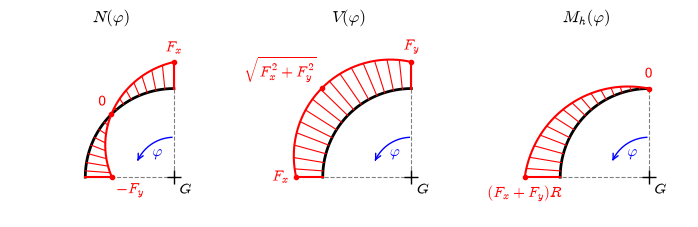

In [11]:
# Számértékek helyettesítése az ábrázoláshoz
ertekek = {F_x: 1, F_y: 1, R: 1}
phi_0f = float(phi_0.subs(ertekek))

# A rúd tengelyvonala és a pozitív oldal felé mutató egységvektor (a görbületi középponttól kifelé)
r = sp.Matrix([-R*sp.sin(phi), R*sp.cos(phi)]).subs(ertekek)
n = sp.Matrix([-sp.sin(phi), sp.cos(phi)])

# Az ábrák: függvény, lépték, cím és a jellemző értékek (helyük, feliratuk és a felirat eltolása)
abrak = [(N, 0.3, r'$N(\varphi)$', [(0, r'$F_x$', None), (phi_0f, r'$0$', None), (np.pi/2, r'$-F_y$', (3, -4))]),
         (V, 0.3, r'$V(\varphi)$', [(0, r'$F_y$', None), (phi_0f, r'$\sqrt{F_x^2 + F_y^2}$', None), (np.pi/2, r'$F_x$', None)]),
         (M_h, 0.2, r'$M_h(\varphi)$', [(0, r'$0$', None), (np.pi/2, r'$(F_x + F_y) R$', (0, -6))])]

fig, axs = plt.subplots(1, 3, figsize=(18/2.54, 8/2.54))
for ax, (f, skala, cim, jellemzok) in zip(axs, abrak):
    rud_menti_abra(ax, f.subs(ertekek), phi, 0, np.pi/2, r, n, skala)
    for t, szoveg, eltolas in jellemzok:
        ertek_felirat(ax, szoveg, f.subs(ertekek), phi, t, r, n, skala, eltolas)
    # A görbületi középpont és a sugarak a rúd két végéhez
    ax.plot([0, 0, -1], [1, 0, 0], color='gray', ls='--', lw=0.8)
    ax.plot(0, 0, '+', color='black', ms=10)
    ax.annotate(r'$G$', xy=(0, 0), xytext=(4, -12), textcoords='offset points', fontsize=11)
    # A φ leíró koordináta iránya: a függőlegestől, az óramutató járásával ellentétesen
    szogek = np.linspace(0.05, 1.1, 30)
    ax.plot(-0.45*np.sin(szogek), 0.45*np.cos(szogek), color='blue', lw=1)
    ax.annotate('', xy=(-0.45*np.sin(1.15), 0.45*np.cos(1.15)), xytext=(-0.45*np.sin(1.05), 0.45*np.cos(1.05)),
                arrowprops=dict(arrowstyle='->', color='blue'))
    ax.annotate(r'$\varphi$', xy=(-0.33*np.sin(0.6), 0.33*np.cos(0.6)), ha='center', va='center', color='blue', fontsize=11)
    ax.set_title(cim)
    ax.set_aspect('equal')
    ax.set_xlim(-1.85, 0.45)
    ax.set_ylim(-0.45, 1.65)
    ax.axis('off')
plt.tight_layout()
plt.savefig('igenybeveteli_abrak_rud_menten.pdf') # Az ábra mentése PDF dokumentumba
plt.show()

##### Igénybevételi ábrák az ívhossz szerint

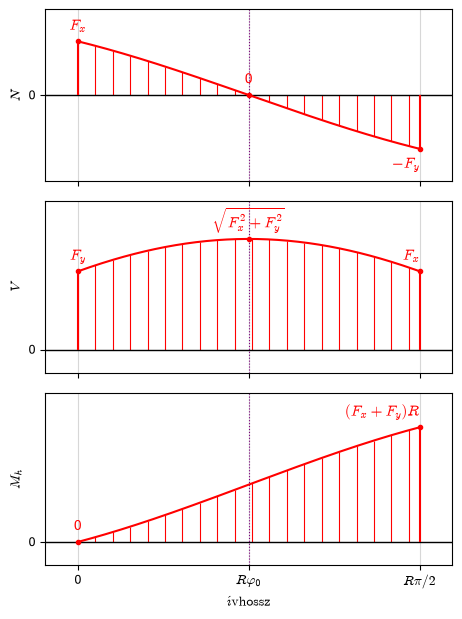

In [12]:
# Az ívhossz a φ függvényében
s = (R*phi).subs(ertekek)

fig, axs = plt.subplots(3, 1, figsize=(12/2.54, 16/2.54), sharex=True)
for ax, (f, skala, cim, jellemzok), felirat in zip(axs, abrak, [r'$N$', r'$V$', r'$M_h$']):
    igenybeveteli_abra(ax, f.subs(ertekek), phi, 0, np.pi/2, s, felirat, lepes=0.08)
    # A jellemző értékek
    for t, szoveg, _ in jellemzok:
        f_t = round(float(f.subs(ertekek).subs(phi, t)), 10)
        ax.plot(float(s.subs(phi, t)), f_t, 'o', color='red', ms=3, zorder=10)
        # A tartomány végén lévő feliratot jobbra igazítjuk, hogy ne lógjon ki az ábrából
        ha = 'right' if t == np.pi/2 else 'center'
        ax.annotate(szoveg, xy=(float(s.subs(phi, t)), f_t), xytext=(0, 8 if f_t >= 0 else -14), textcoords='offset points', ha=ha, color='red', fontsize=11)
    ax.set_yticks([0], [r'$0$'])
    # A szélsőérték helye
    ax.axvline(phi_0f, color='purple', ls=':', lw=0.8)

axs[0].set_ylim(-1.6, 1.6)
axs[1].set_ylim(-0.3, 1.9)
axs[2].set_ylim(-0.4, 2.6)
axs[2].set_xticks([0, phi_0f, np.pi/2], [r'$0$', r'$R \varphi_0$', r'$R \pi / 2$'])
axs[2].set_xlim(-0.15, np.pi/2 + 0.15)
axs[2].set_xlabel(r'$\acute{\imath}\mathrm{vhossz}$') # Az "í" betű nincs benne a cmr10 betűtípusban, ezért mathtext-tel írjuk
plt.tight_layout()
plt.savefig('igenybeveteli_fuggvenyek.pdf') # Az ábra mentése PDF dokumentumba
plt.show()

A hajlítónyomaték a befogásnál a legnagyobb: $M_h(\pi/2) = (F_x + F_y) R$, a nyíróerő pedig a $\varphi_0$ helyen, ahol a normálerő előjelet vált.